# OpenLattice: physics-checked assistant for perovskite solar-cell literature
Run the cells top to bottom. Cell 2 loads the model (about 1 minute), then use the form in cell 3.

In [1]:
import duckdb, numpy as np, matplotlib.pyplot as plt
import physics_checks as pc, agent
con = duckdb.connect("lattice.duckdb", read_only=True)
n_all = con.execute("select count(*) from cells").fetchone()[0]
n_bad = con.execute("select count(*) from cells where any_bad").fetchone()[0]
print(f"{n_all:,} records; {n_bad:,} ({100*n_bad/n_all:.1f}%) fail at least one physics check")
agent.generate([{"role":"user","content":"hi"}], 5)   # loads the model once
print("model loaded")

42,443 records; 1,737 (4.1%) fail at least one physics check


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

model loaded


In [2]:
import ipywidgets as w
from IPython.display import display, clear_output, Markdown
EX = {
 "Best efficiency, 1.5-1.6 eV window": "What is the highest power conversion efficiency reported for a perovskite solar cell with bandgap of at least 1.5 eV and strictly below 1.6 eV?",
 "Impossible claim (1.9 eV, 28 %)": "Which paper reported a perovskite solar cell with a 1.9 eV bandgap reaching 28% power conversion efficiency? Give the DOI.",
 "Impossible Voc": "Which paper reported a perovskite cell with a 1.6 eV bandgap and an open-circuit voltage of 1.9 V? Give the DOI.",
 "Count high-efficiency nip cells": "How many nip-architecture perovskite cells report at least 24% power conversion efficiency?",
 "Out of scope": "Who won the 2022 football world cup?"}
pick = w.Dropdown(options=list(EX), description="Example", layout=w.Layout(width="500px"))
q = w.Textarea(value=EX[pick.value], description="Question", layout=w.Layout(width="900px", height="70px"))
mode = w.RadioButtons(options=["Compare both", "Physics gate ON", "Physics gate OFF"], description="Mode")
go = w.Button(description="Ask OpenLattice", button_style="success")
out = w.Output()
pick.observe(lambda c: setattr(q, "value", EX[c["new"]]), names="value")
LABEL = {"answered":"ANSWERED","refused_impossible":"REFUSED: PHYSICALLY IMPOSSIBLE","out_of_scope":"OUT OF SCOPE","failed":"COULD NOT ANSWER"}
def show(tag, r):
    print(f"\n=== Gate {tag}: {LABEL[r['status']]} ===")
    print(r["answer"])
    c = {k:v for k,v in r["claims"].items() if v is not None}
    if c: print("Claims detected:", c, "| Shockley-Queisser limit:", r["sq_limit"], "%")
    for n in r["notes"]: print("WARNING:", n)
    if r["table"] is not None and len(r["table"]): display(r["table"])
    if r["sql"]: print("SQL:", r["sql"])
def on_go(_):
    with out:
        clear_output(); print("thinking...")
        runs = []
        if mode.value != "Physics gate OFF": runs.append(("ON", agent.ask(q.value, True, con)))
        if mode.value != "Physics gate ON": runs.append(("OFF", agent.ask(q.value, False, con)))
        clear_output()
        for t, r in runs: show(t, r)
go.on_click(on_go)
display(w.VBox([pick, q, mode, go, out]))

## Check any claim yourself

In [3]:
@w.interact(eg=w.FloatSlider(value=1.55, min=0.9, max=3.3, step=0.01, description="Bandgap eV", layout=w.Layout(width="500px")),
            pce=w.FloatSlider(value=26, min=1, max=40, step=0.1, description="Claim %", layout=w.Layout(width="500px")))
def check(eg, pce):
    ok, msg = pc.check_solar(pce, eg)
    g = np.arange(0.9, 3.3, 0.02)
    fig, ax = plt.subplots(figsize=(6, 3.4))
    ax.plot(g, [pc.sq_limit(x) for x in g], "k", label="Shockley-Queisser limit")
    ax.scatter([eg], [pce], c="#2a9d8f" if ok else "#D1495B", s=60, zorder=3, label="your claim")
    ax.set_xlabel("Bandgap (eV)"); ax.set_ylabel("Efficiency (%)"); ax.legend(frameon=False)
    print(("OK: " if ok else "IMPOSSIBLE: ") + msg); plt.show()

interactive(children=(FloatSlider(value=1.55, description='Bandgap eV', layout=Layout(width='500px'), max=3.3,…

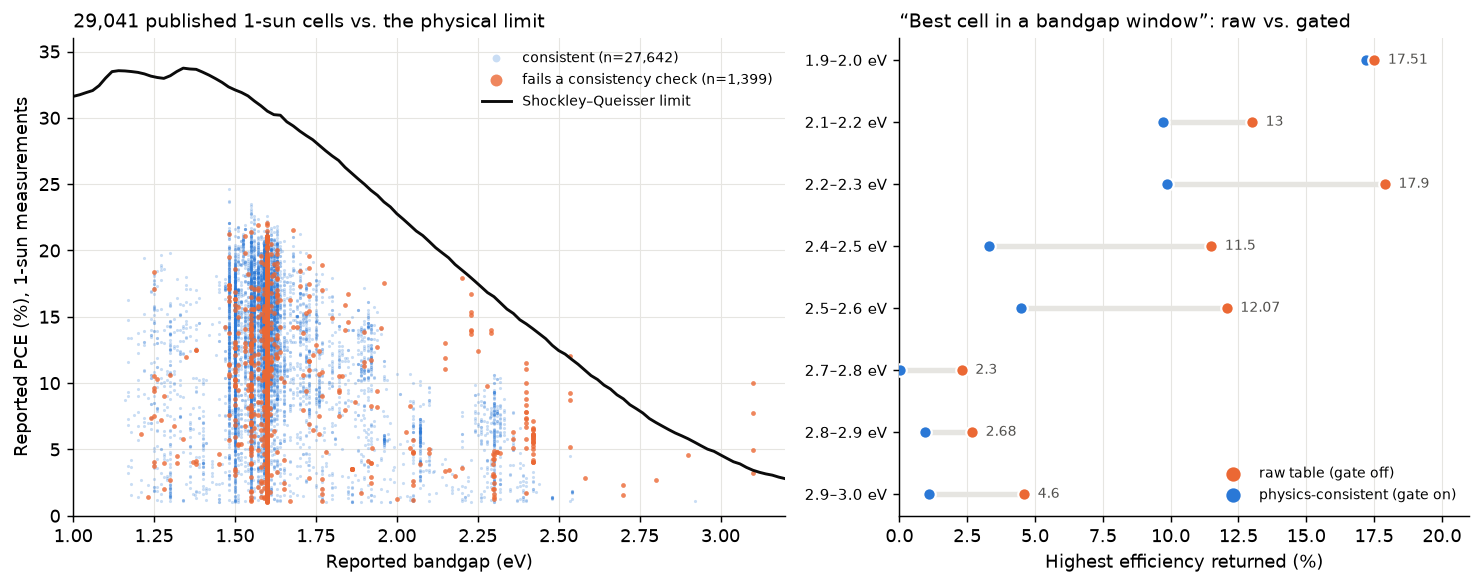

In [4]:
import json
import matplotlib.pyplot as plt
BLUE, ORG, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e1"
d = con.execute("select eg, pce, any_bad from cells where std_illum and pce>1 and eg between 1 and 3.3 "
                "and voc is not null and jsc is not null and ff is not null and arch not ilike '%tandem%'").fetchdf()
Q = sorted([q for q in json.load(open("questions.json")) if q["type"] == "max_pce" and q["raw"] > q["truth"] + 0.05], key=lambda q: q["a"])
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.6), dpi=130, gridspec_kw={"width_ratios": [1.25, 1]})
a = ax[0]; ok = d[~d.any_bad]; bad = d[d.any_bad]
a.scatter(ok.eg, ok.pce, s=3, alpha=.25, color=BLUE, lw=0, label=f"consistent (n={len(ok):,})")
a.scatter(bad.eg, bad.pce, s=7, alpha=.8, color=ORG, lw=0, label=f"fails a consistency check (n={len(bad):,})")
g = np.arange(1.0, 3.3, 0.02); a.plot(g, [pc.sq_limit(x) for x in g], color=INK, lw=1.6, label="Shockley–Queisser limit")
a.set_xlim(1, 3.2); a.set_ylim(0, 36); a.set_xlabel("Reported bandgap (eV)"); a.set_ylabel("Reported PCE (%), 1-sun measurements")
a.set_title(f"{len(d):,} published 1-sun cells vs. the physical limit", loc="left", fontsize=10.5)
a.legend(frameon=False, fontsize=8, loc="upper right", markerscale=2.5)
b = ax[1]
for i, q in enumerate(Q):
    b.plot([q["truth"], q["raw"]], [i, i], color=GRID, lw=3, solid_capstyle="round", zorder=1)
    b.scatter(q["truth"], i, s=48, color=BLUE, zorder=3, edgecolor="white", lw=1.2)
    b.scatter(q["raw"], i, s=48, color=ORG, zorder=3, edgecolor="white", lw=1.2)
    b.text(q["raw"] + .5, i, f"{q['raw']:g}", va="center", fontsize=8, color=MUTED)
b.set_yticks(range(len(Q))); b.set_yticklabels([f"{q['a']:.1f}–{q['b']:.1f} eV" for q in Q], fontsize=8.5); b.invert_yaxis()
b.set_xlim(0, 21); b.set_xlabel("Highest efficiency returned (%)")
b.set_title("“Best cell in a bandgap window”: raw vs. gated", loc="left", fontsize=10.5)
b.scatter([], [], s=48, color=ORG, label="raw table (gate off)"); b.scatter([], [], s=48, color=BLUE, label="physics-consistent (gate on)")
b.legend(frameon=False, fontsize=8, loc="lower right")
for x in ax:
    x.grid(axis="both" if x is a else "x", color=GRID, lw=.6); x.set_axisbelow(True)
    for s in ("top", "right"): x.spines[s].set_visible(False)
fig.tight_layout(); fig.savefig("openlattice_results.png", dpi=170); plt.show()